In [53]:
# Cell 1: Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print('Libraries loaded successfully!')

Libraries loaded successfully!


In [54]:
# Cell 2: Load data
df = pd.read_csv('../data/raw/exoplanets.csv')

print('Shape:', df.shape)
df.head()

Shape: (4855, 12)


,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,1.04,5750,NaN
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,1.07,5736,NaN
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,1.08,5892,Proper name Taphao Thong
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,1.12,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,0.905,5196,Proper name Galileo


In [55]:
# Cell 3: Explore columns and missing values
print(df.columns.tolist())
print('\nMissing values per column:')
print(df.isnull().sum())

['Name', 'Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Temp. (K)', 'Discovery method', 'Disc. Year', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)', 'Remarks']

Missing values per column:
Name                       0
Mass (MJ)               2560
Radius (RJ)             1155
Period (days)            218
Semi-major axis (AU)    1707
Temp. (K)               3761
Discovery method           0
Disc. Year              4444
Distance (ly)            149
Host star mass (M☉)      380
Host star temp. (K)      342
Remarks                  353
dtype: int64


In [56]:
df = df.drop(['Disc. Year', 'Remarks'], axis=1, errors='ignore')


In [57]:
df.head()

,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Distance (ly),Host star mass (M☉),Host star temp. (K)
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,radial vel.,68.99,1.04,5750
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,radial vel.,85.46,1.07,5736
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,radial vel.,45.02,1.08,5892
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,radial vel.,50.45,1.12,5793
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,radial vel.,41.06,0.905,5196


In [58]:
df.drop(['Discovery method','Distance(ly)'], axis=1, errors='ignore')

,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Distance (ly),Host star mass (M☉),Host star temp. (K)
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,68.99,1.04,5750
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,85.46,1.07,5736
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,45.02,1.08,5892
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,50.45,1.12,5793
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,41.06,0.905,5196
...,...,...,...,...,...,...,...,...,...
4850,BD-210397 b,0.7±0.1,NaN,1891+56−48,2.63+0.06−0.05,NaN,77.4046+0.0744−0.0740,0.679±0.017,4051±239
4851,BD-210397 c,2.4+1.5−0.7,NaN,6360+6260−711,5.9+3.4−0.5,NaN,77.4046+0.0744−0.0740,0.679±0.017,4051±239
4852,EPIC 229004835 b,0.0327+0.0050−0.0047,0.2080+0.0071−0.0084,16.141132±0.000019,0.1237±0.0017,804±10,398.255+2.867−2.825,0.970±0.040,5868±60
4853,GJ 1151 c,0.03341+0.00412−0.00463,NaN,389.7+5.4−6.5,0.5714+0.0053−0.0064,NaN,26.21071+0.02518−0.02515,0.1639±0.0093,3280±40


In [59]:
df.head()

,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Distance (ly),Host star mass (M☉),Host star temp. (K)
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,radial vel.,68.99,1.04,5750
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,radial vel.,85.46,1.07,5736
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,radial vel.,45.02,1.08,5892
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,radial vel.,50.45,1.12,5793
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,radial vel.,41.06,0.905,5196


In [60]:
print(df.columns.tolist())
print('Missing value')
print(df.isnull().sum())
df.shape

['Name', 'Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Temp. (K)', 'Discovery method', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)']
Missing value
Name                       0
Mass (MJ)               2560
Radius (RJ)             1155
Period (days)            218
Semi-major axis (AU)    1707
Temp. (K)               3761
Discovery method           0
Distance (ly)            149
Host star mass (M☉)      380
Host star temp. (K)      342
dtype: int64


(4855, 10)

In [61]:
rows_with_missing = df.isnull().any(axis=1).sum()
total_rows = len(df)
print(f"Rows with ≥1 missing value : {rows_with_missing} / {total_rows}  ({rows_with_missing/total_rows*100:.1f}%)")


Rows with ≥1 missing value : 4170 / 4855  (85.9%)


In [62]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %':    (df.isnull().sum() / total_rows * 100).round(1)
}).sort_values('Missing %', ascending=False)
print("\nPer-column breakdown:")
print(missing_summary[missing_summary['Missing Count'] > 0])


Per-column breakdown:
                      Missing Count  Missing %
Temp. (K)                      3761       77.5
Mass (MJ)                      2560       52.7
Semi-major axis (AU)           1707       35.2
Radius (RJ)                    1155       23.8
Host star mass (M☉)             380        7.8
Host star temp. (K)             342        7.0
Period (days)                   218        4.5
Distance (ly)                   149        3.1


In [63]:
print("\nCorrelation of missingness between columns:")
print(df.isnull().corr().round(2))


Correlation of missingness between columns:
                      Name  Mass (MJ)  Radius (RJ)  Period (days)  \
Name                   NaN        NaN          NaN            NaN   
Mass (MJ)              NaN       1.00        -0.58          -0.22   
Radius (RJ)            NaN      -0.58         1.00           0.34   
Period (days)          NaN      -0.22         0.34           1.00   
Semi-major axis (AU)   NaN       0.47        -0.35          -0.14   
Temp. (K)              NaN       0.38         0.18           0.06   
Discovery method       NaN        NaN          NaN            NaN   
Distance (ly)          NaN      -0.02        -0.07          -0.01   
Host star mass (M☉)    NaN       0.23        -0.12          -0.02   
Host star temp. (K)    NaN      -0.16         0.28           0.62   

                      Semi-major axis (AU)  Temp. (K)  Discovery method  \
Name                                   NaN        NaN               NaN   
Mass (MJ)                             0.47   

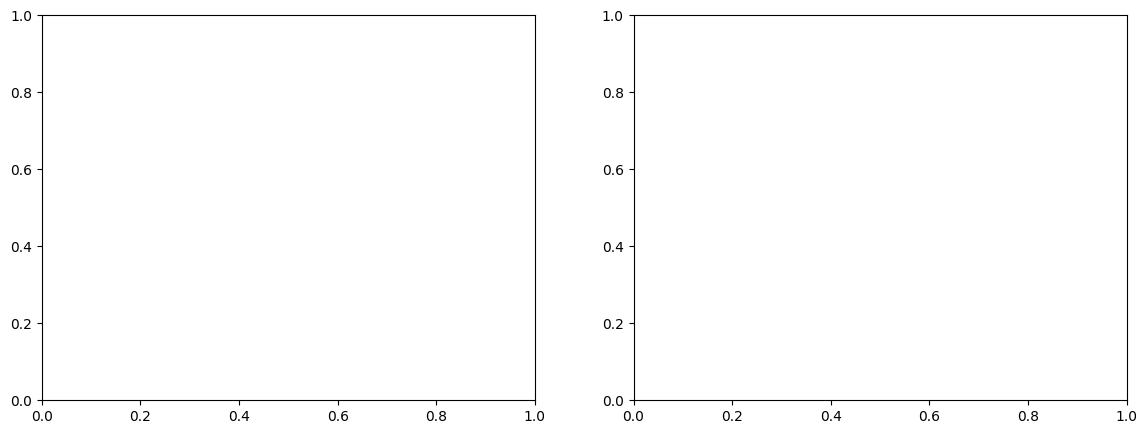

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

In [65]:
sample = df.sample(min(500, total_rows), random_state=42)
sns.heatmap(sample.isnull(), cbar=False, yticklabels=False,
            cmap='viridis', ax=axes[1])
axes[1].set_title('Missing Value Pattern (500-row sample)\nYellow = missing')
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

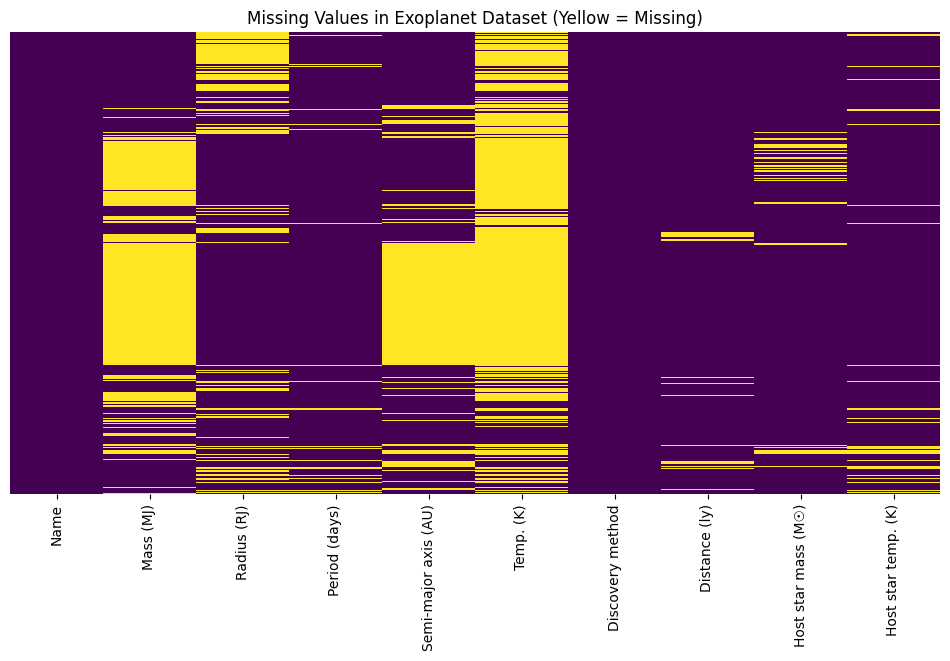

In [70]:
import seaborn as sns
import matplotlib.pyplot as pyplot

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')


plt.title('Missing Values in Exoplanet Dataset (Yellow = Missing)')
plt.show()

NameError: name 'X' is not defined